# Herhalingslabo Classificatie

Hoe weet je wanneer je welk algoritme best gebruikt ? Gebruik volgende handleiding:

**KNearestNeighbours**
- Geschikt voor classificatie en regressie
- Voor kleine/middelgrote datasets
- heel simpel, kan snel worden getrained
- werkt niet goed voor datasets met heel veel features

**Support Vector Machines**
- Vooral een standaard voor binaire classificatie, of wanneer je een duidelijke marge wilt op classificatie (=het hoofddoel van het algoritme)
- Voor kleine/middelgrote datasets
- Is kostelijker om te trainen dan KNN, maar classificeert dan wel sneller
- Kernel keuze en hyperparameter tuning zijn essentieel

**Decision Trees**
- Wanneer je een 'white box', 'explainable' model wilt
- kan zowel numerieke als categorische features makkelijk aan
- kan heel goed om met missende datapunten
- het risico op overfitting is groot. Bij twijfel, gebruik een random forest

**Random forest**
- Zelfde voordelen als decision tree, minder risico op overfitting
- Geschikt voor middelgrote/grote datasets
- Geschikt voor data met (heel) veel features
- Hebben uiteraard meer trainingstijd nodig dan een enkele decision tree

**Adaboost**
- Als data niet goed is gebalanceerd (niet evenveel items van elke klasse)
- Vermijd een onderfit. Dit model is beter dan 1 enkele onderliggende decision tree

**XGBoost**
- XGBoost is bijna *altijd* een goede keuze
- Middelgrote / grote datasets
- Datasets met (heel) veel features
- De implementatie van XGBoost staat, ondanks dat het een boosting algoritme is, toch deels parallellisatie toe.

In de praktijk zijn er vaak meerdere goede keuzes. Het is belangrijk te weten waarom een bepaald model wel/niet een goede keuze zou zijn, en vervolgens de meest veelbelovende modellen te proberen en te kijken wat het beste werkt.

### Wat is een kleine / middelgrote / grote dataset ?

Uiteraard is dat een beetje afhankelijk van hoelang je bereid bent te wachten. In deze cursus gebruiken we de gangbare regel:
- Klein: <10k
- Middelgroot: 10k - 100k
- Groot: >100k

Dit is ongetwijfeld over een paar jaar volledig voorbijgestreefd. Besef dat je in real life dit altijd moet afwegen tegenover de beschikbare compute power, op een Raspberry Pi 3 zal een middelgrote dataset al een stevige trainingstijd hebben, terwijl dat kinderspel is op een cloud compute server.

## Oefeningen

Behandel de volgende 3 datasets - je kan ze downloaden vanop Digitap. Lees in, bekijk, en beoordeel welke algoritmes het meeste zin hebben. Pas de ML algoritmes toe en rapporteer de uiteindelijke score van je model.
- Diabetes - i de 'outcome' kolom wordt aangegeven of mensen diabetes hebben
- Customer Churn: in commerciële setting wordt vaak gesproken van 'churn', oftewel het aangeven in een soort diagram waar klanten in een process afhaken. Deze dataset bevat een 'churn' kolom die dat codeert.
- Creditcard bevat data die reeds door een ander algoritme is gegaan, waardoor de kolommen geen herkenbare naam meer hebben. De laatste kolom wijst op fraude (1) of een valide transactie (0).

In [251]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
diabetes = pd.read_csv('diabetes.csv')
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
(768, 9)


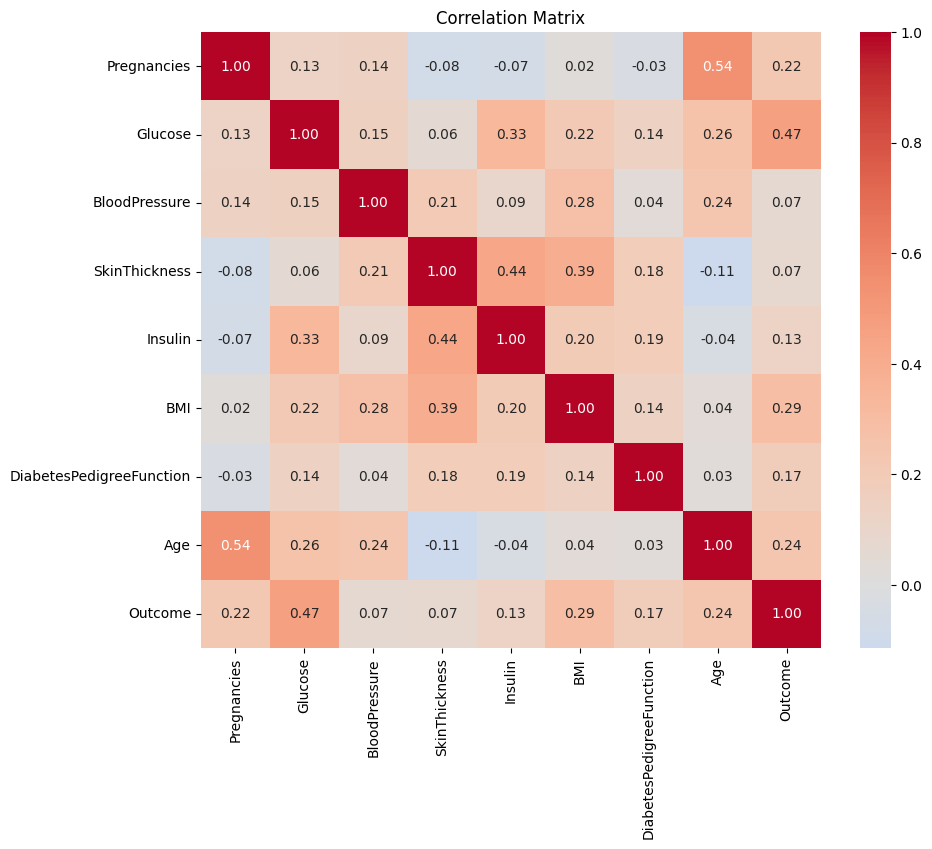

In [252]:
print(diabetes.isna().sum())
print(diabetes.shape)
plt.figure(figsize=(10, 8))
sns.heatmap(
    data=diabetes.corr(),
    annot=True, # Show values
    cmap='coolwarm', # Color map
    center=0, # Center color at 0
    fmt=".2f" # Decimal formatting
)
plt.title('Correlation Matrix')
plt.show()

In [253]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
X = diabetes.copy()
if 'Outcome' in X.columns:
    X.drop(columns=['Outcome'], inplace=True)
print(X.shape)
y = diabetes['Outcome']
print(y.head(5))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

svm_classifier = SVC(kernel='linear')
svm_classifier.fit(X_train, y_train)

preds = svm_classifier.predict(X_test)

accu_svm = accuracy_score(y_test, preds)
print(accu_svm)

(768, 8)
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64
0.7597402597402597


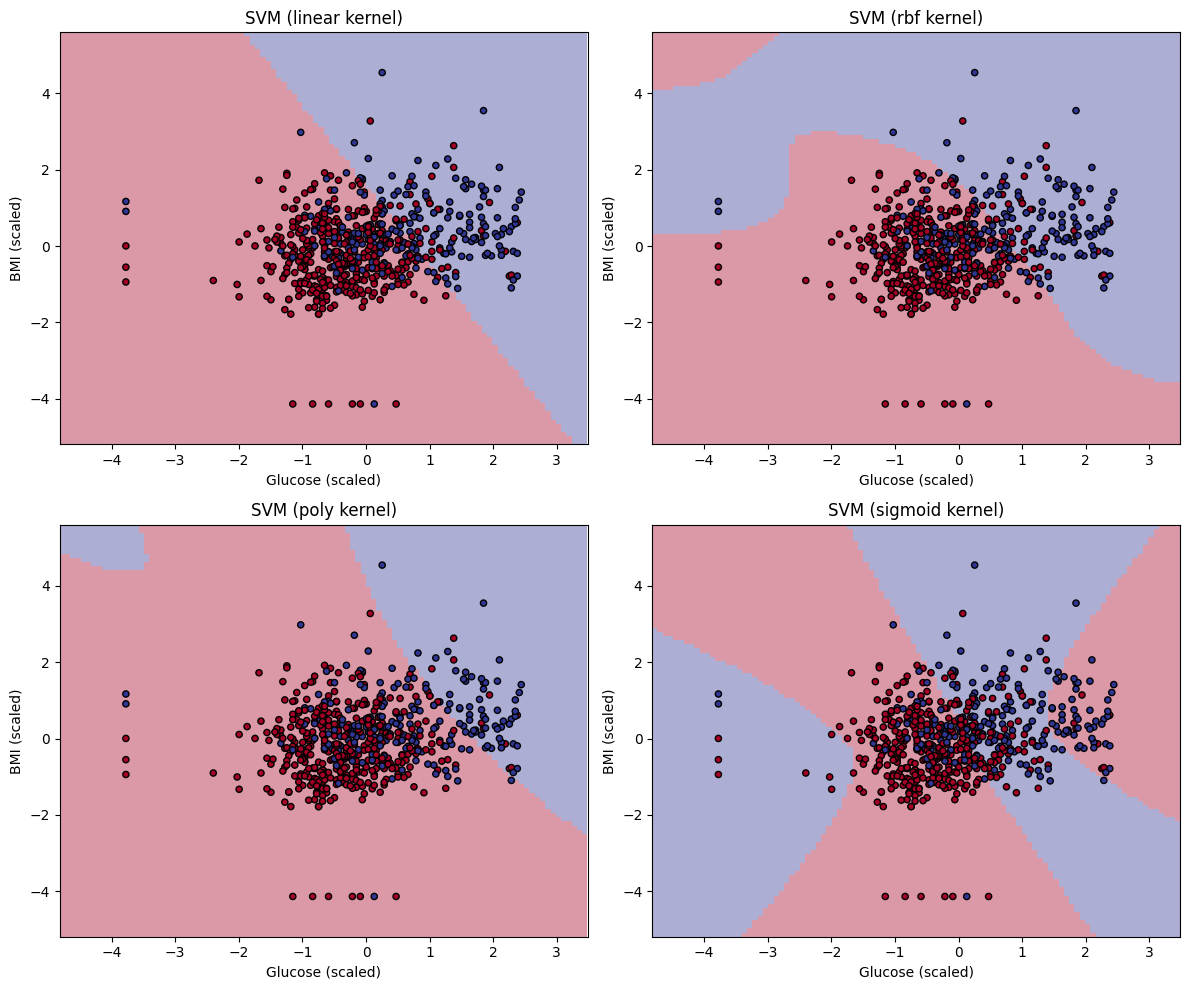

In [254]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

selected_features = ['Glucose', 'BMI']
idx = [X.columns.get_loc(f) for f in selected_features]
X_2d = X_train[:, idx]          # let op: X_train is hier al geschaald

kernels = ['linear', 'rbf', 'poly', 'sigmoid']
titles = [f"SVM ({kernel} kernel)" for kernel in kernels]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, kernel, title in zip(axes, kernels, titles):
    # Fit SVM
    svm = SVC(kernel=kernel)
    svm.fit(X_2d, y_train)

    # Plot decision boundary
    DecisionBoundaryDisplay.from_estimator(
        svm,
        X_2d,
        response_method="predict",
        plot_method="pcolormesh",
        cmap=plt.cm.RdYlBu,
        shading="auto",
        alpha=0.4,
        ax=ax,
    )

    # Scatter plot of training data
    ax.scatter(
        X_2d[:, 0],
        X_2d[:, 1],
        c=y_train,
        cmap=plt.cm.RdYlBu,
        edgecolor="k",
        s=20,
    )
    ax.set_xlabel(f"{selected_features[0]} (scaled)")
    ax.set_ylabel(f"{selected_features[1]} (scaled)")
    ax.set_title(title)

plt.tight_layout()
plt.show()


In [255]:
churn = pd.read_csv('Telco-Customer-Churn.csv')
churn.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [256]:
churn.index = churn['customerID']
churn.drop(columns=['customerID'], inplace=True)
print(churn.shape)
print(churn.dtypes)
print(churn.describe(include=['object']))

(7043, 20)
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
       gender Partner Dependents PhoneService MultipleLines InternetService  \
count    7043    7043       7043         7043          7043            7043   
unique      2       2          2            2             3               3   
top      Male      No         No          Yes            No     Fiber optic   
freq     3555    3641       4933         6361          3390            3096   

       OnlineSecuri

In [257]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
le = LabelEncoder()
churn['Churn'] = le.fit_transform(churn['Churn'])
churn.head()
labeling_features = ['gender', 'Partner', 'Dependents', 'PhoneService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
for i in labeling_features:
    churn[i] = le.fit_transform(churn[i])

onehot_features = ['MultipleLines', 'InternetService']
churn = pd.get_dummies(churn, columns=onehot_features, drop_first=True)
churn = churn.drop(churn[churn.TotalCharges == ' '].index)
churn['TotalCharges'] = churn['TotalCharges'].astype(float)

for i in ['MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No']:
    churn[i] = churn[i].astype(int)

churn.dtypes

gender                              int64
SeniorCitizen                       int64
Partner                             int64
Dependents                          int64
tenure                              int64
PhoneService                        int64
OnlineSecurity                      int64
OnlineBackup                        int64
DeviceProtection                    int64
TechSupport                         int64
StreamingTV                         int64
StreamingMovies                     int64
Contract                            int64
PaperlessBilling                    int64
PaymentMethod                       int64
MonthlyCharges                    float64
TotalCharges                      float64
Churn                               int64
MultipleLines_No phone service      int64
MultipleLines_Yes                   int64
InternetService_Fiber optic         int64
InternetService_No                  int64
dtype: object

In [258]:
X = churn.copy()
if 'Churn' in X.columns:
    X.drop(columns=['Churn'], inplace=True)
print(X.shape)
y = churn['Churn']
print(y.head(5))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

(7032, 21)
customerID
7590-VHVEG    0
5575-GNVDE    0
3668-QPYBK    1
7795-CFOCW    0
9237-HQITU    1
Name: Churn, dtype: int64


In [259]:
from sklearn.ensemble import VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

knn_classifier = KNeighborsClassifier(5)
decision_tree_classifier = DecisionTreeClassifier(random_state=42)
svm_classifier = SVC(probability=True)
xgb_classifier = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=10, random_state=42)

voting_classifier = VotingClassifier(
    estimators=[
        ('knn', knn_classifier),
        ('dtreec', decision_tree_classifier),
        ('svmc', svm_classifier),
        ('xgb', xgb_classifier)
    ],
    voting='hard')

voting_classifier.fit(X_train, y_train)
y_pred = voting_classifier.predict(X_test)
accuracy_voting = accuracy_score(y_test, y_pred)
print(accuracy_voting)

individual_estimators = [knn_classifier, decision_tree_classifier, svm_classifier, xgb_classifier]
for estimator in individual_estimators:
    estimator.fit(X_train, y_train)
    y_pred = estimator.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy van {estimator.__class__.__name__}: {accuracy:.4f}")

/opt/venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


0.7924662402274343
Accuracy van KNeighborsClassifier: 0.7463
Accuracy van DecisionTreeClassifier: 0.7178


/opt/venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy van SVC: 0.7925
Accuracy van XGBClassifier: 0.7790


In [ ]:
def grid_search_xgb(X_train, y_train, X_test, y_test, n_estims, lrs, depths):
    best_score, best_cfg = 0.0, None
    for n in n_estims:
        for r in lrs:
            for d in depths:
                try:
                    xgb: XGBClassifier = XGBClassifier(n_estimators=n, learning_rate=r, max_depth=d, random_state=42)
                    xgb.fit(X_train, y_train)
                    preds = xgb.predict(X_test)
                    accu = accuracy_score(y_test, preds)
                except Exception:
                    continue
                if accu > best_score:
                    best_score, best_cfg = accu, (n, r, d)

    return best_score, best_cfg

nest, lrss, deps = [10, 50, 100, 150, 300], [0.001, 0.01, 0.1, 1, 3], [3, 5, 10, 20, 50]

best_score_xg, best_cfg_xg = grid_search_xgb(X_train, y_train, X_test, y_test, nest, lrss, deps)

print(best_score_xg, best_cfg_xg)

0.7960199004975125 (300, 0.01, 10)


In [261]:
cards = pd.read_csv('creditcard.csv')
cards.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
